# ============================================================
# 1. IMPORTS
# =============================================================================================================


In [41]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.tree import export_text

# ============================================================
# 2. GLOBAL VISUALIZATION CONFIGURATION
# ===========

In [2]:

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep"

)
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.autolayout": True
})

# Pandas display configuration

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:.3f}".format)

print("Environment configured successfully!")


Environment configured successfully!


In [4]:
# Load the iris dataset
iris = load_iris(as_frame=True)
# Extract features and target
df = iris.frame.copy()

In [5]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.100,3.500,1.400,0.200,0
1,4.900,3.000,1.400,0.200,0
2,4.700,3.200,1.300,0.200,0
3,4.600,3.100,1.500,0.200,0
4,5.000,3.600,1.400,0.200,0


In [6]:
df["target"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

In [7]:
df = df.rename(columns={"target":"species"})

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [9]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.100,3.500,1.400,0.200,setosa
1,4.900,3.000,1.400,0.200,setosa
2,4.700,3.200,1.300,0.200,setosa
3,4.600,3.100,1.500,0.200,setosa
4,5.000,3.600,1.400,0.200,setosa


In [10]:
df["species"].unique()

<StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str

In [11]:
df.shape

(150, 5)

### What are we predicting?
#### Feature	        Meaning
##### sepal length (cm)	Length of the outer flower part
##### sepal width (cm)	Width of the outer flower part
##### petal length (cm)	Length of the inner flower part
##### petal width (cm)	Width of the inner flower part
##### species	Species we want to predict

Our prediction problem: Given the measurements of an Iris flower, predict whether it belongs to:
- Iris setosa
- Iris versicolor
- Iris virginica
This is multiclass classification because we have three possible categories.

In [12]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000,150.000,150.000,150.000
mean,5.843,3.057,3.758,1.199
std,0.828,0.436,1.765,0.762
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.350,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


In [13]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

In [14]:
print(df[df.duplicated()])

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)    species
142              5.800             2.700              5.100             1.900  virginica


In [15]:
df = df.drop_duplicates()

In [16]:
class_counts = df["species"].value_counts()


In [17]:
class_counts

species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64

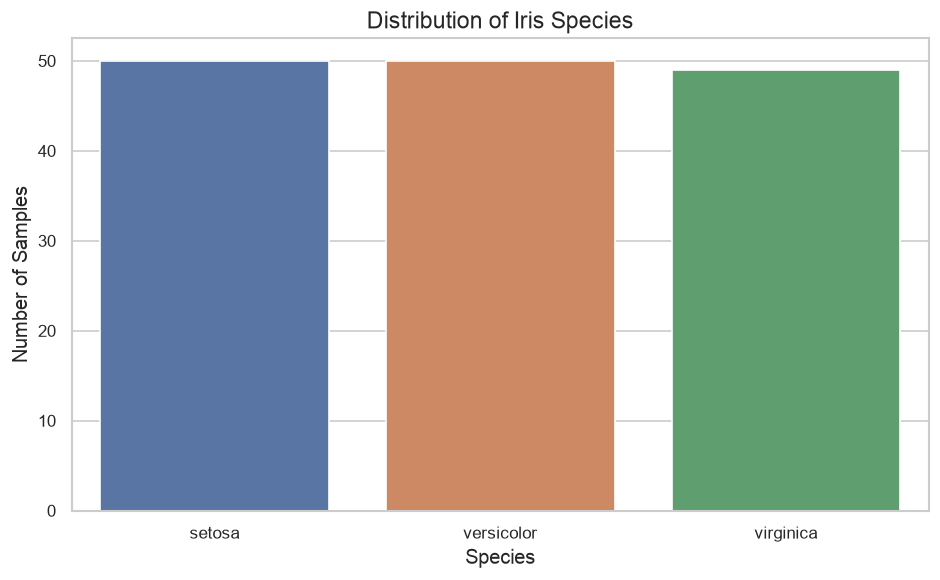

In [18]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x="species",
    hue="species",
    legend=False
)

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")
plt.show()

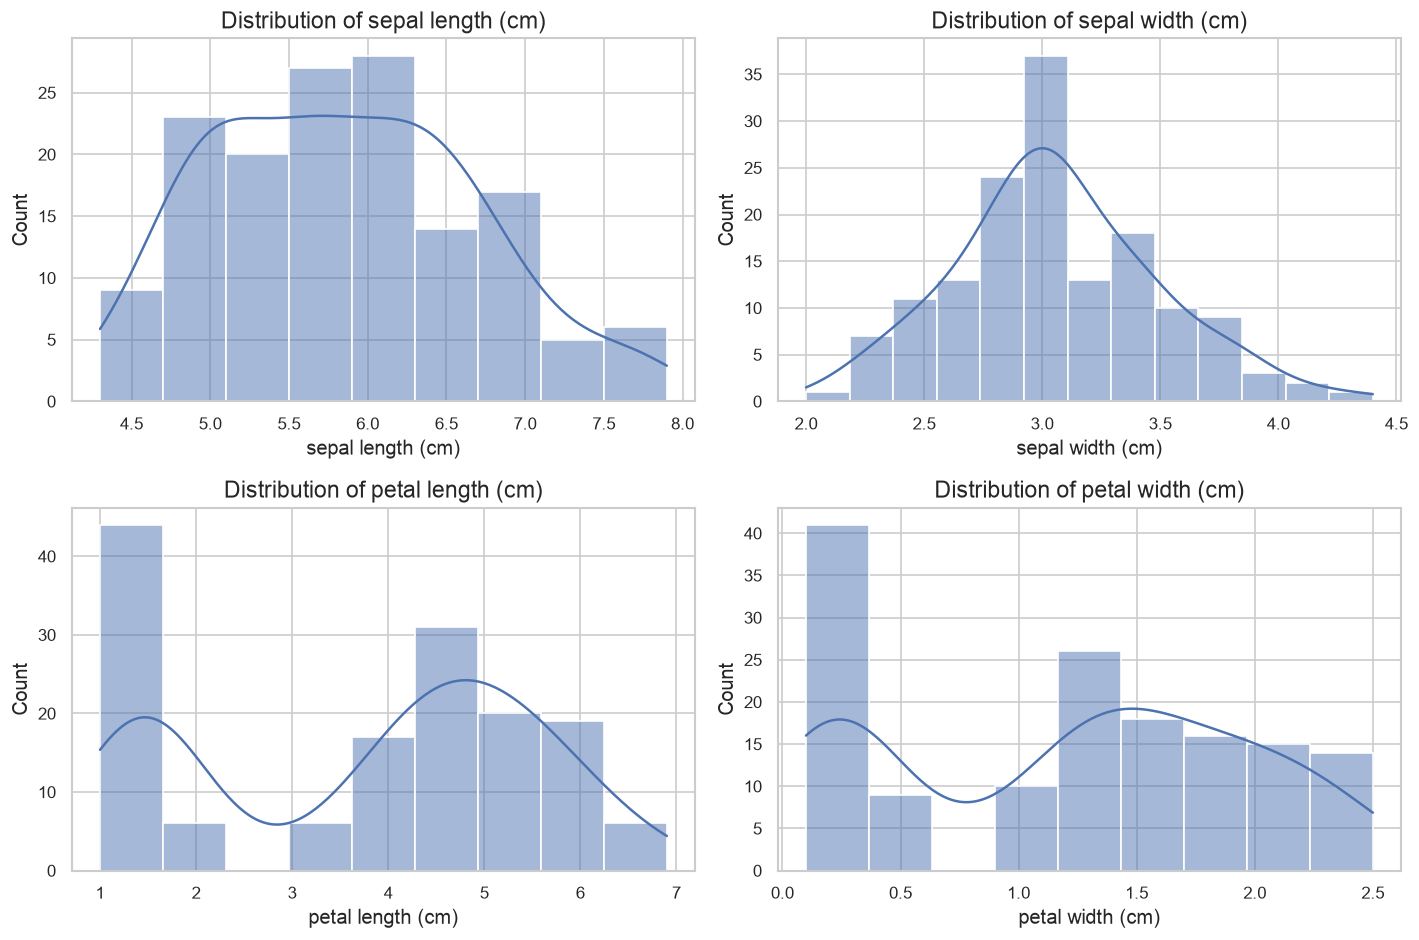

In [19]:
feature_columns = iris.feature_names

fig,axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(12,8)
)
axes = axes.flatten()

for i,feature in enumerate(feature_columns):
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

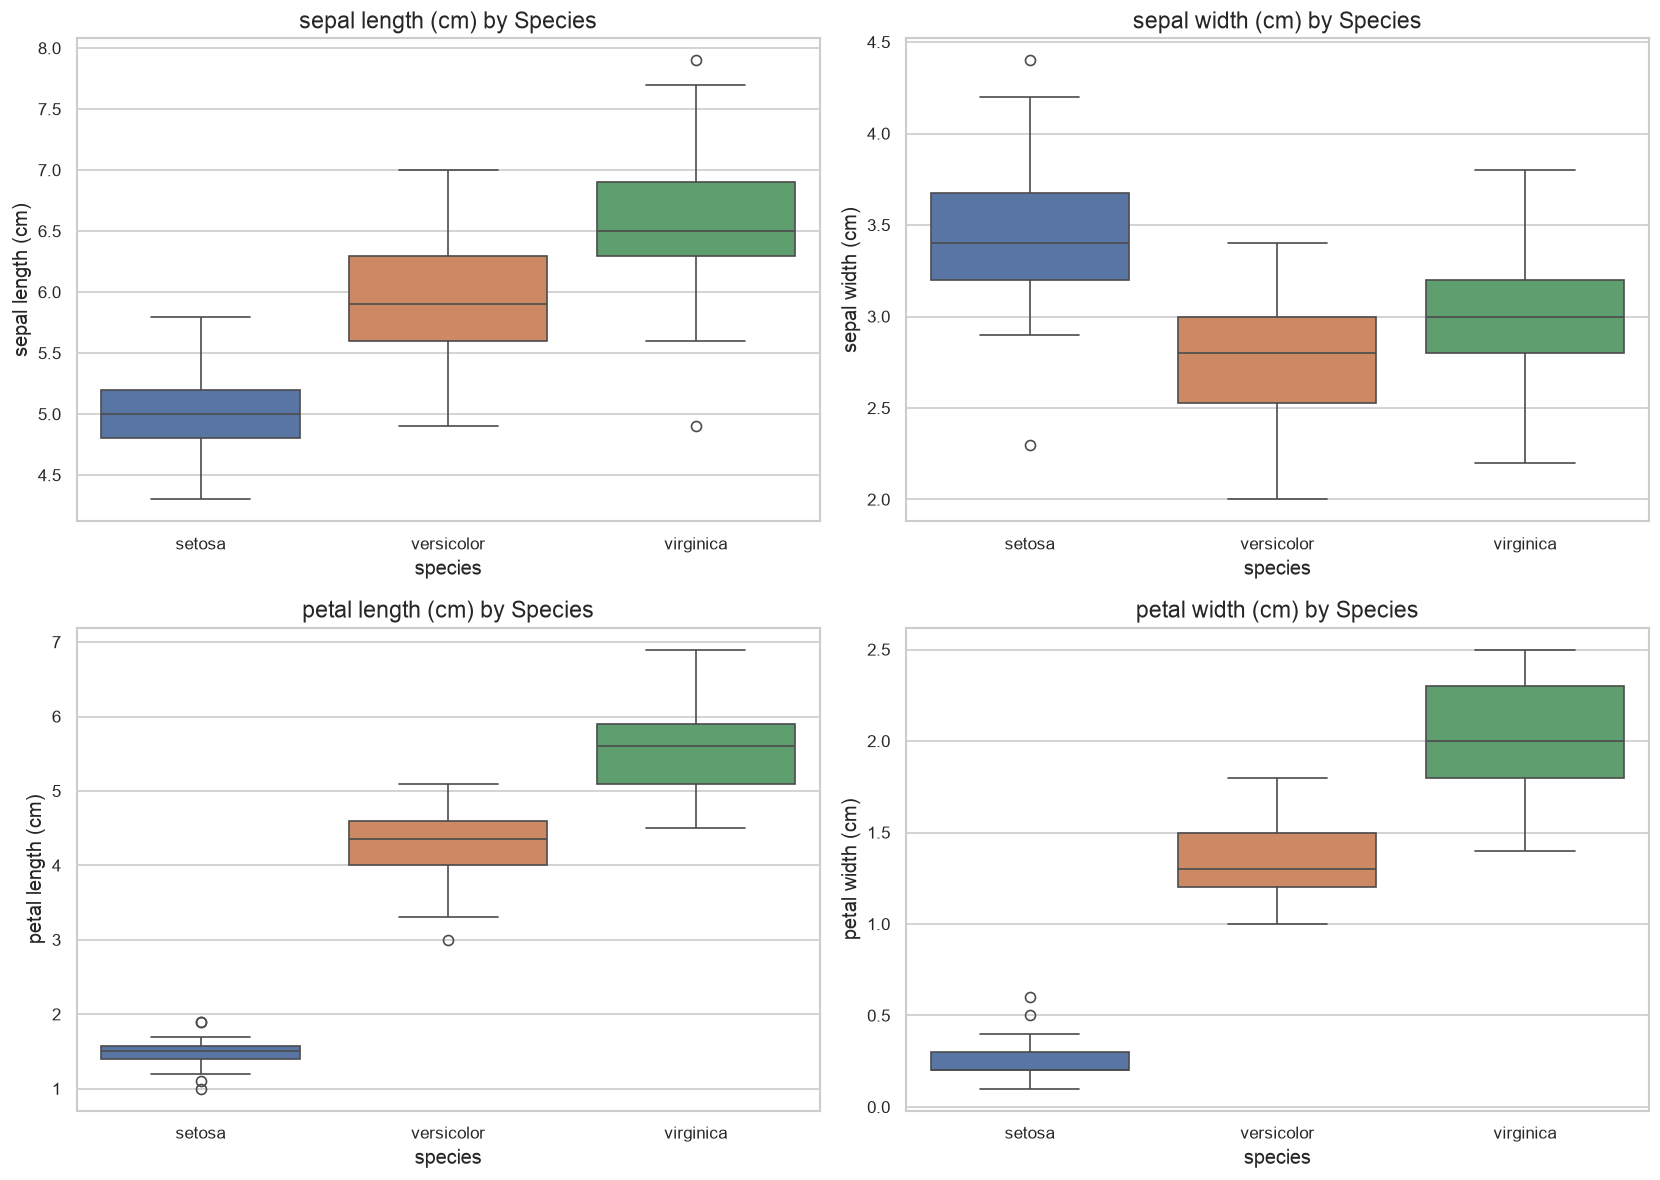

In [20]:
fig,axes= plt.subplots(
    2,
    2,
    figsize=(14,10)
)

axes = axes.flatten()

for i,feature in enumerate(feature_columns):
    sns.boxplot(
        data=df,
        x='species',
        y = feature,
        hue='species',
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} by Species")
plt.tight_layout()
plt.show()


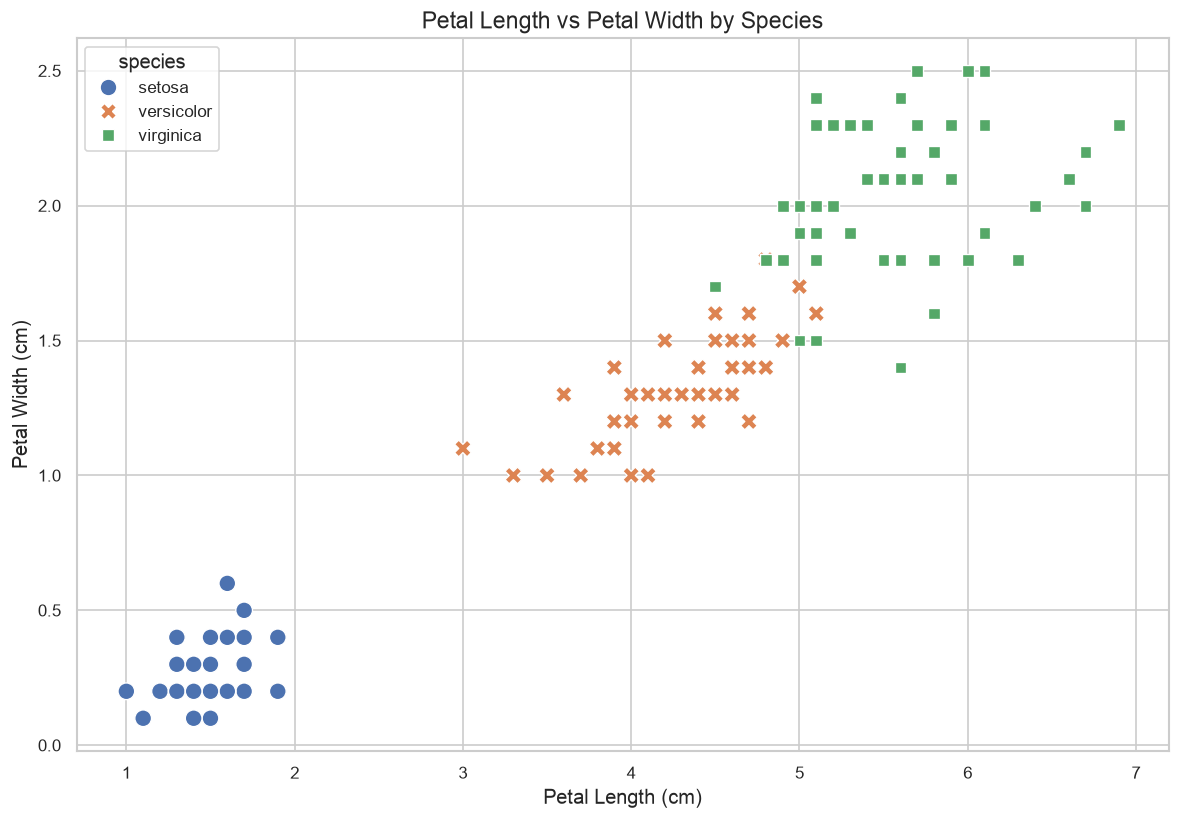

In [21]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    style="species",
    s=100
)

plt.title("Petal Length vs Petal Width by Species")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")

plt.show()

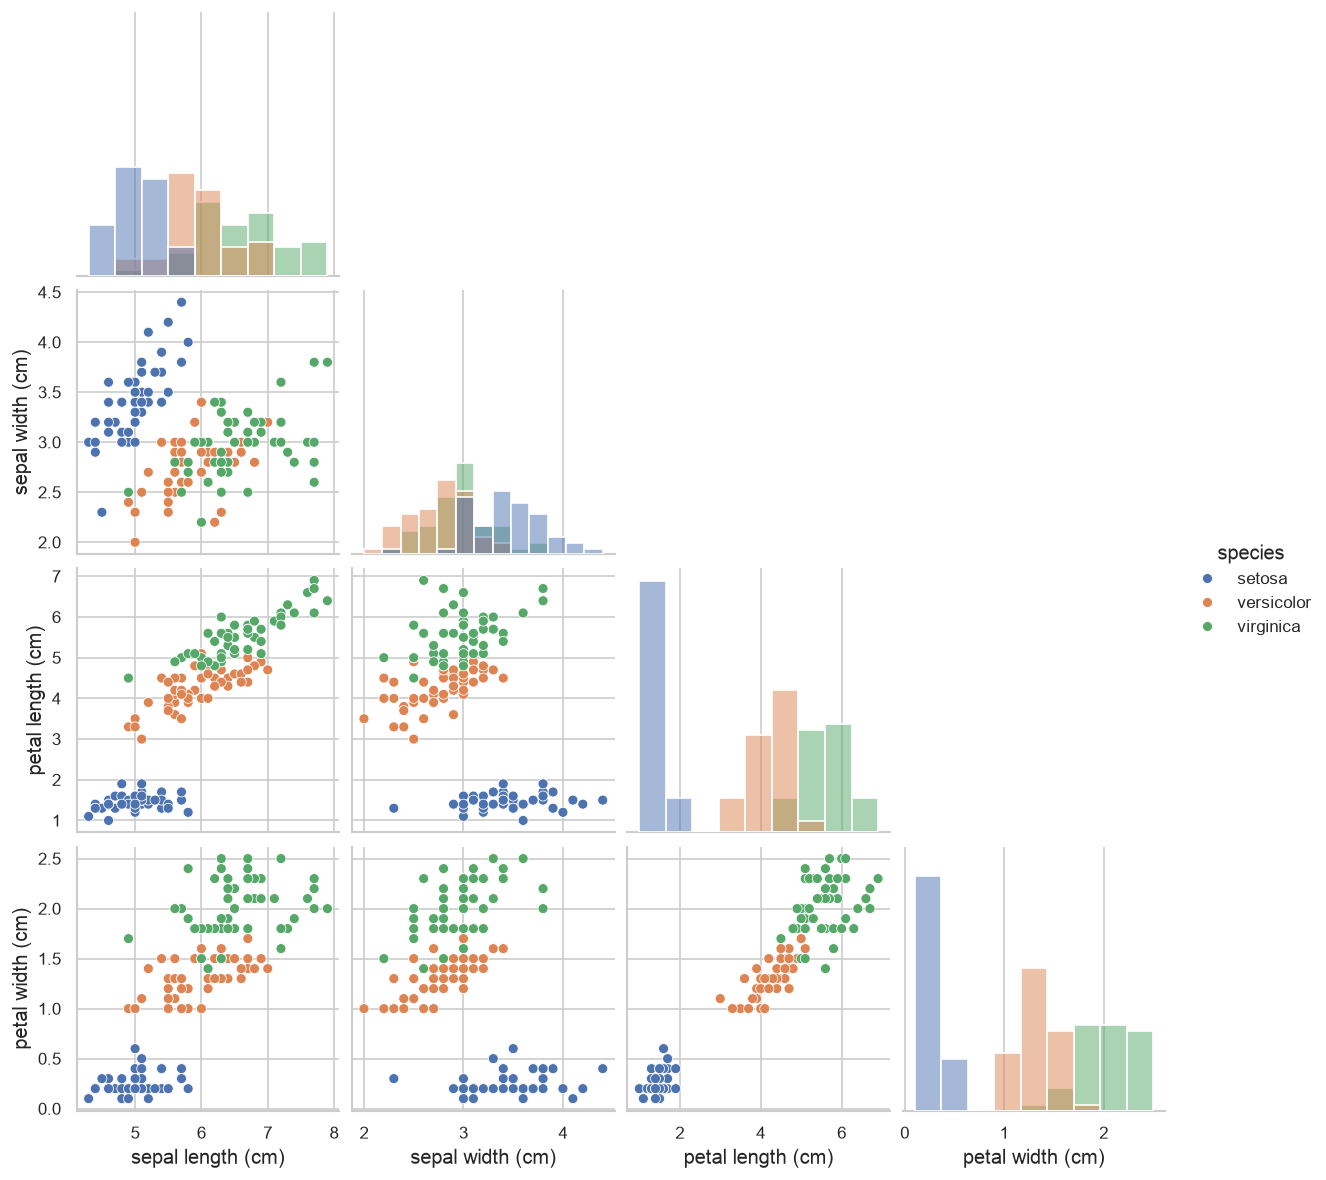

In [22]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist",
    corner=True
)

plt.show()

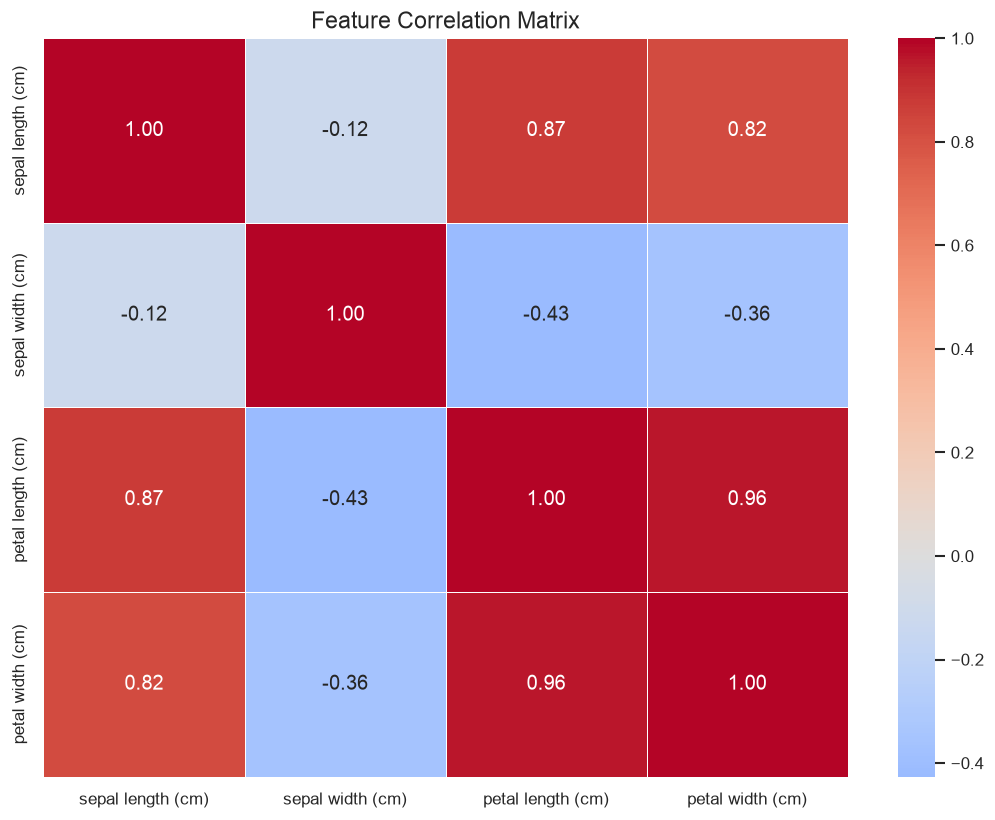

In [23]:
corr_matrix = df[feature_columns].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Feature Correlation Matrix")

plt.show()

## EDA Findings and Observations

### 1. Dataset Cleaning
During data quality inspection, one duplicate observation belonging to the Virginica class was identified and removed. This resulted in the removal of one duplicate record from the dataset.

### 2. Feature Distributions
- **Sepal Length:** The distribution is relatively broad, with most observations concentrated around the middle range. It appears somewhat asymmetric but is not strongly skewed.
- **Sepal Width:** The distribution appears approximately unimodal and reasonably centered around 3 cm.
- **Petal Length and Petal Width:** Both features exhibit multiple concentrations rather than a single uniform distribution. This may reflect the differences between the three Iris species.

### 3. Outlier Analysis
Boxplots revealed several potential outliers in sepal length, sepal width, petal length, and petal width across different species.

These observations were identified using the boxplot visualization and should not automatically be considered erroneous. Further investigation would be necessary before removing them.

### 4. Feature Relationships
The scatter plot of Petal Length versus Petal Width demonstrates substantial separation between the three species, particularly for Setosa. Versicolor and Virginica show some overlap, indicating that distinguishing between these classes may be comparatively more challenging.

### 5. Correlation Analysis
The correlation matrix revealed a very strong positive correlation between Petal Length and Petal Width (approximately 0.96).

Sepal Length also demonstrated strong positive correlations with Petal Length (approximately 0.87) and Petal Width (approximately 0.82).

Sepal Width showed weaker negative correlations with the petal measurements.

### 6. Preliminary Conclusion
The dataset appears suitable for a multiclass classification task. Petal Length and Petal Width appear particularly informative for distinguishing between the Iris species. This hypothesis will be investigated through classification models and evaluation metrics in the subsequent analysis.

In [24]:
X = df[iris.feature_names]

y = df["species"]

print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

Features:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.100,3.500,1.400,0.200
1,4.900,3.000,1.400,0.200
2,4.700,3.200,1.300,0.200
3,4.600,3.100,1.500,0.200
4,5.000,3.600,1.400,0.200



Target:


0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: str

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
display(y_train.value_counts())

print("\nTesting class distribution:")
display(y_test.value_counts())

Training samples: 119
Testing samples: 30

Training class distribution:


species
setosa        40
versicolor    40
virginica     39
Name: count, dtype: int64


Testing class distribution:


species
versicolor    10
virginica     10
setosa        10
Name: count, dtype: int64

In [26]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`

In [27]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","[np.str_('setosa'),np.str_('versicolor'),np.str_('virginica')]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['sepal length (cm)','sepal width (cm)','petal length (cm)', 'petal width (cm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [28]:
test_predictions = model.predict(X_test)



In [29]:
train_predictions = model.predict(X_train)
train_accuracy = accuracy_score(
    y_train,
    train_predictions
)

test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy:  {test_accuracy:.4f}")

Training Accuracy: 0.9580
Testing Accuracy:  0.9333


In [30]:
precision_macro = precision_score(
    y_test,
    test_predictions,
    average="macro"
)

recall_macro = recall_score(
    y_test,
    test_predictions,
    average="macro"
)

f1_macro = f1_score(
    y_test,
    test_predictions,
    average="macro"
)

print("=" * 50)
print("MODEL EVALUATION")
print("=" * 50)

print(f"Macro Precision:   {precision_macro:.4f}")
print(f"Macro Recall:      {recall_macro:.4f}")
print(f"Macro F1-Score:    {f1_macro:.4f}")

MODEL EVALUATION
Macro Precision:   0.9333
Macro Recall:      0.9333
Macro F1-Score:    0.9333


In [31]:
print(classification_report(
    y_test,
    test_predictions,
    digits=4
))

              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



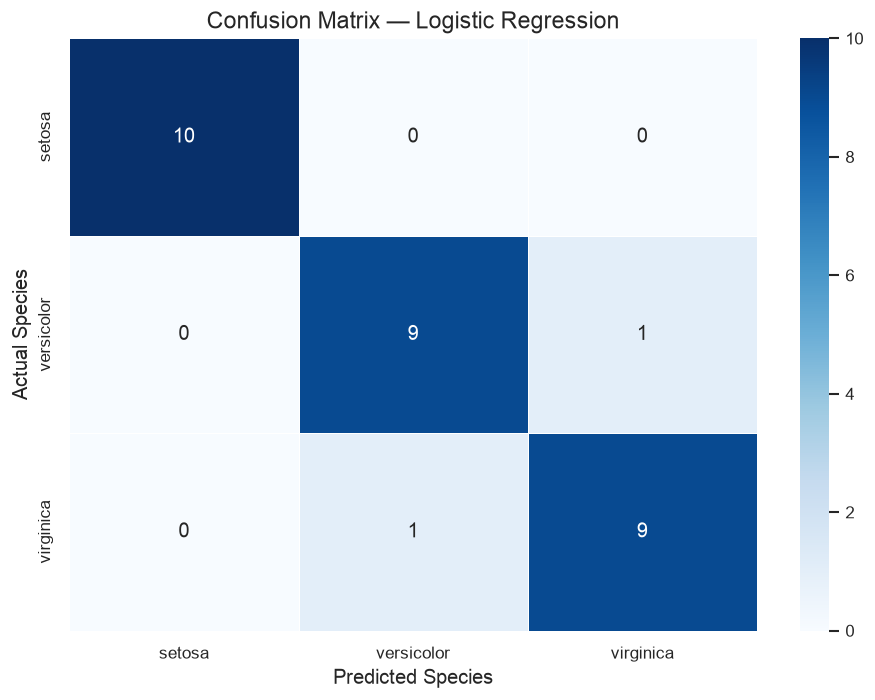

In [32]:
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=model.classes_
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_,
    linewidths=0.5
)

plt.title("Confusion Matrix — Logistic Regression")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.tight_layout()

plt.savefig(
    "../Graphs/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
report = classification_report(
    y_test,
    test_predictions,
    output_dict=True
)

class_metrics = pd.DataFrame(report).T

display(
    class_metrics.loc[
        model.classes_,
        ["precision", "recall", "f1-score", "support"]
    ]
)

,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,10.000
versicolor,0.900,0.900,0.900,10.000
virginica,0.900,0.900,0.900,10.000


## Decision Tree


In [35]:
tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

tree_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [36]:
tree_predictions = tree_model.predict(X_test)

print("Predictions:")
print(tree_predictions)

print("\nActual values:")
print(y_test.to_numpy())

Predictions:
[np.str_('versicolor') np.str_('versicolor') np.str_('virginica')
 np.str_('setosa') np.str_('virginica') np.str_('versicolor')
 np.str_('versicolor') np.str_('setosa') np.str_('virginica')
 np.str_('virginica') np.str_('setosa') np.str_('setosa')
 np.str_('setosa') np.str_('versicolor') np.str_('virginica')
 np.str_('setosa') np.str_('virginica') np.str_('setosa')
 np.str_('virginica') np.str_('setosa') np.str_('versicolor')
 np.str_('virginica') np.str_('setosa') np.str_('setosa')
 np.str_('versicolor') np.str_('versicolor') np.str_('virginica')
 np.str_('virginica') np.str_('virginica') np.str_('versicolor')]

Actual values:
[np.str_('versicolor') np.str_('versicolor') np.str_('virginica')
 np.str_('setosa') np.str_('virginica') np.str_('versicolor')
 np.str_('versicolor') np.str_('setosa') np.str_('virginica')
 np.str_('virginica') np.str_('setosa') np.str_('setosa')
 np.str_('setosa') np.str_('versicolor') np.str_('virginica')
 np.str_('setosa') np.str_('versicolor') 

In [37]:
tree_accuracy = accuracy_score(y_test, tree_predictions)

tree_precision = precision_score(
    y_test,
    tree_predictions,
    average="macro"
)

tree_recall = recall_score(
    y_test,
    tree_predictions,
    average="macro"
)

tree_f1 = f1_score(
    y_test,
    tree_predictions,
    average="macro"
)

print("=" * 50)
print("DECISION TREE EVALUATION")
print("=" * 50)

print(f"Accuracy:         {tree_accuracy:.4f}")
print(f"Macro Precision:  {tree_precision:.4f}")
print(f"Macro Recall:     {tree_recall:.4f}")
print(f"Macro F1:         {tree_f1:.4f}")

DECISION TREE EVALUATION
Accuracy:         0.9667
Macro Precision:  0.9697
Macro Recall:     0.9667
Macro F1:         0.9666


In [38]:
print(classification_report(
    y_test,
    tree_predictions,
    target_names=iris.target_names,
    digits=4
))

              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    0.9000    0.9474        10
   virginica     0.9091    1.0000    0.9524        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30



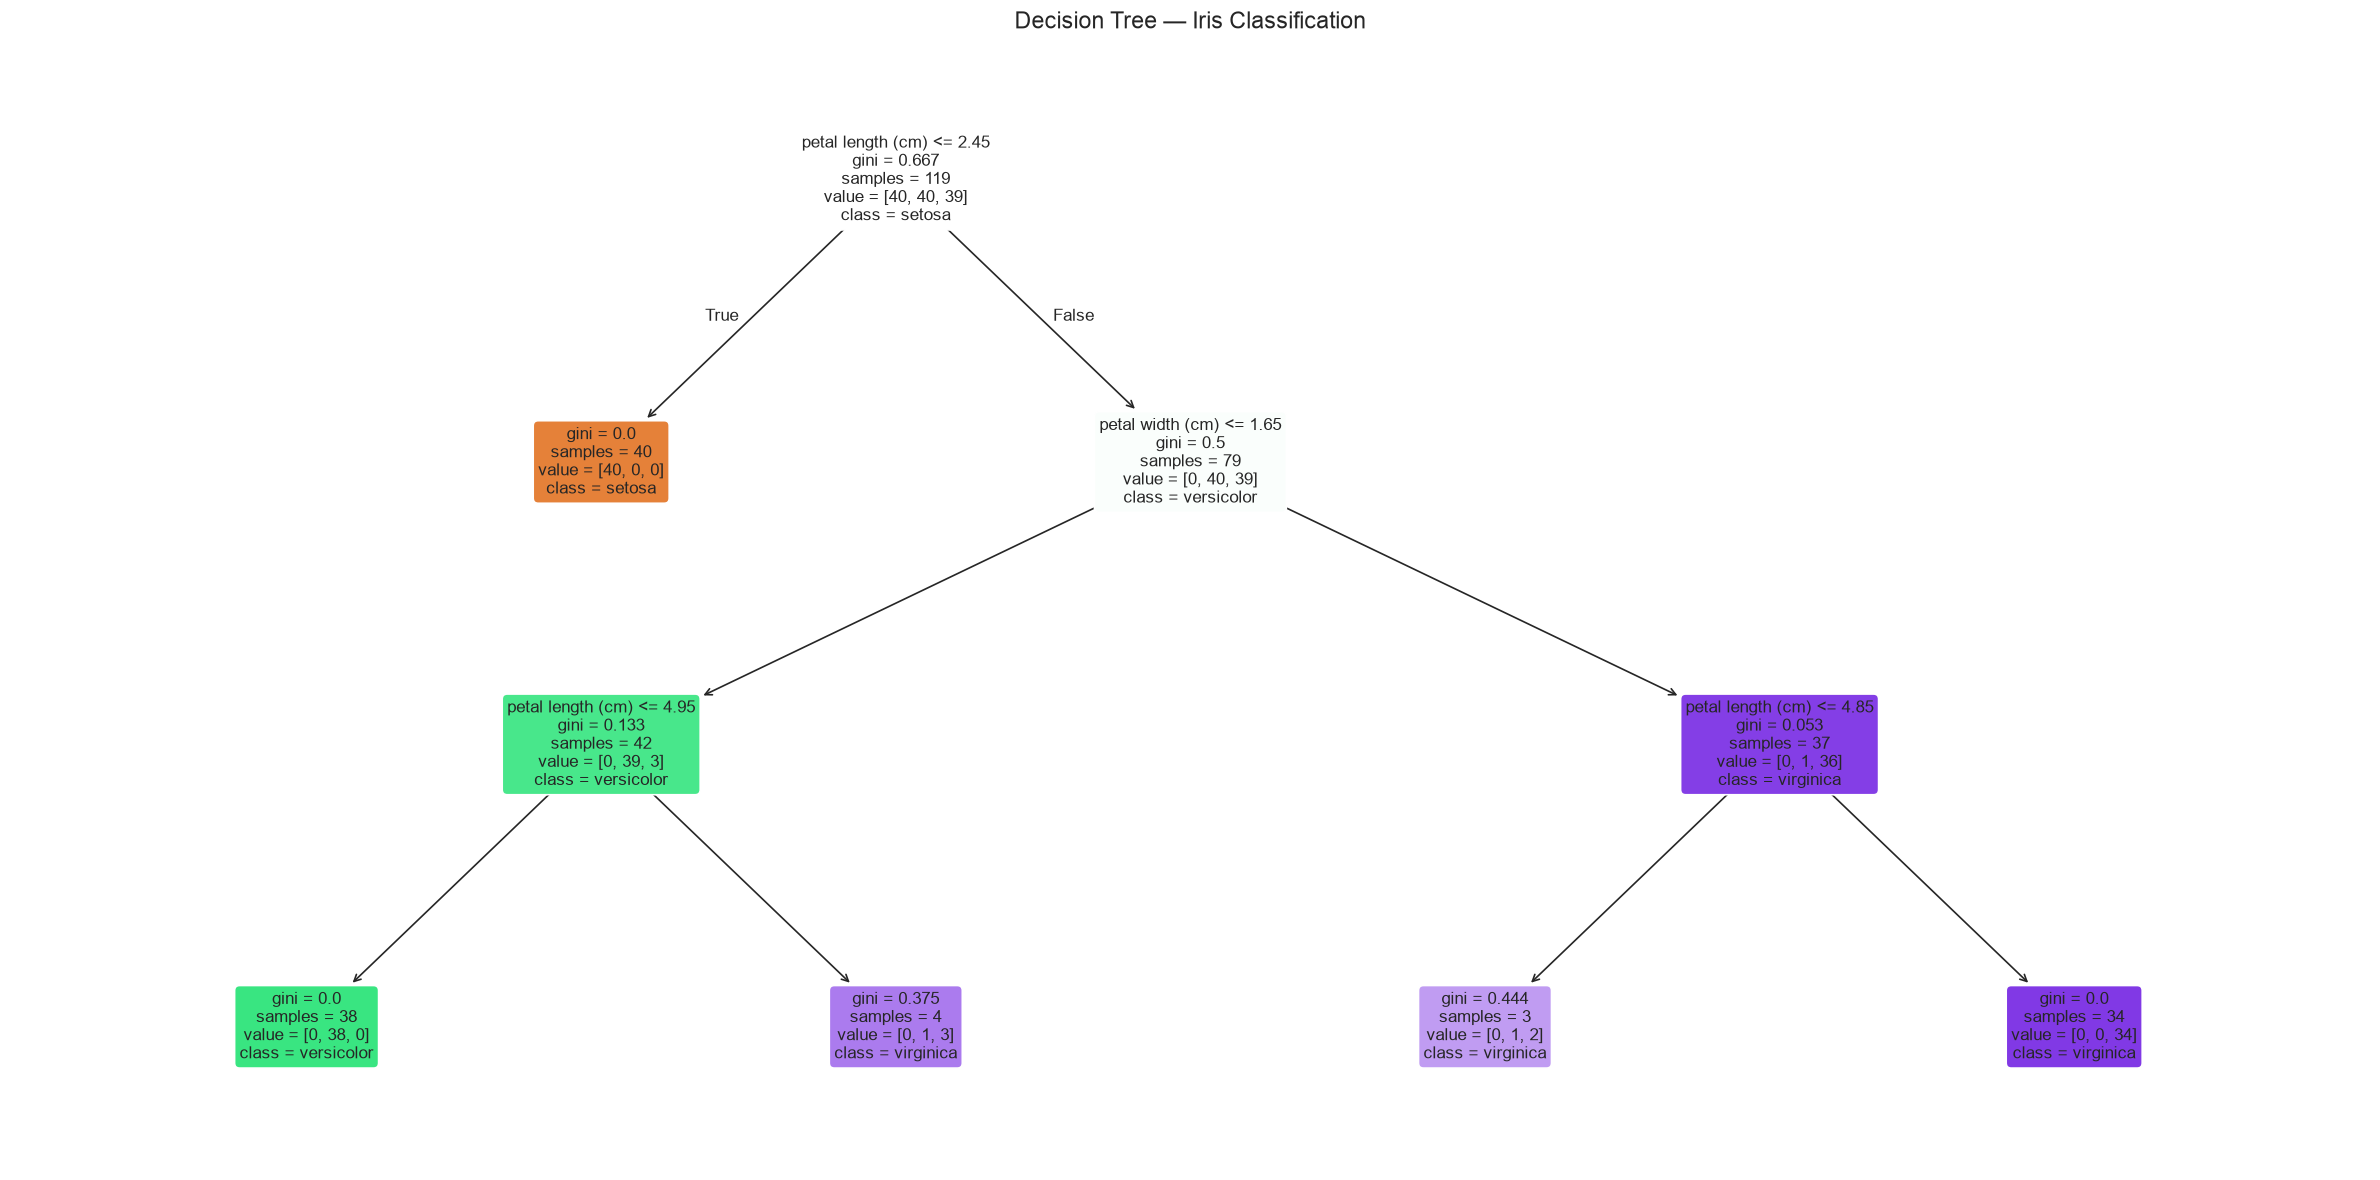

In [40]:
plt.figure(figsize=(20, 10))

plot_tree(
    tree_model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree — Iris Classification")

plt.tight_layout()

plt.show()

In [42]:
tree_rules = export_text(
    tree_model,
    feature_names=iris.feature_names
)

print(tree_rules)

|--- petal length (cm) <= 2.45
|   |--- class: setosa
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.65
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: versicolor
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: virginica
|   |--- petal width (cm) >  1.65
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- class: virginica
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: virginica



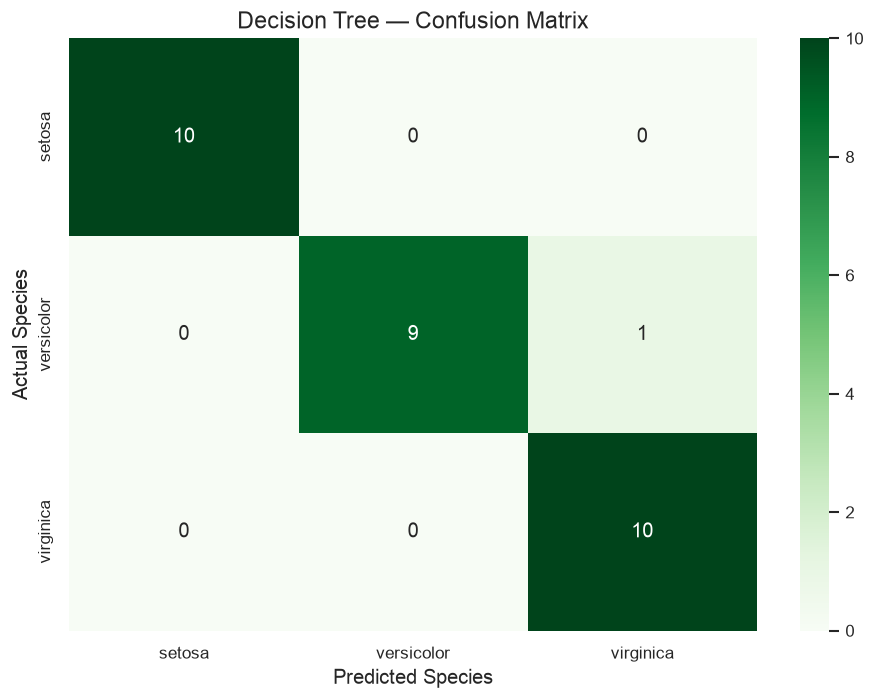

In [43]:
cm_tree = confusion_matrix(
    y_test,
    tree_predictions,
    labels=tree_model.classes_
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Decision Tree — Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.tight_layout()

plt.show()

In [45]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        accuracy_score(y_test, test_predictions),
        accuracy_score(y_test, tree_predictions)
    ],
    "Macro Precision": [
        precision_score(y_test, test_predictions, average="macro"),
        precision_score(y_test, tree_predictions, average="macro")
    ],
    "Macro Recall": [
        recall_score(y_test, test_predictions, average="macro"),
        recall_score(y_test, tree_predictions, average="macro")
    ],
    "Macro F1": [
        f1_score(y_test, test_predictions, average="macro"),
        f1_score(y_test, tree_predictions, average="macro")
    ]
})

display(comparison.round(4))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.933,0.933,0.933,0.933
1,Decision Tree,0.967,0.970,0.967,0.967


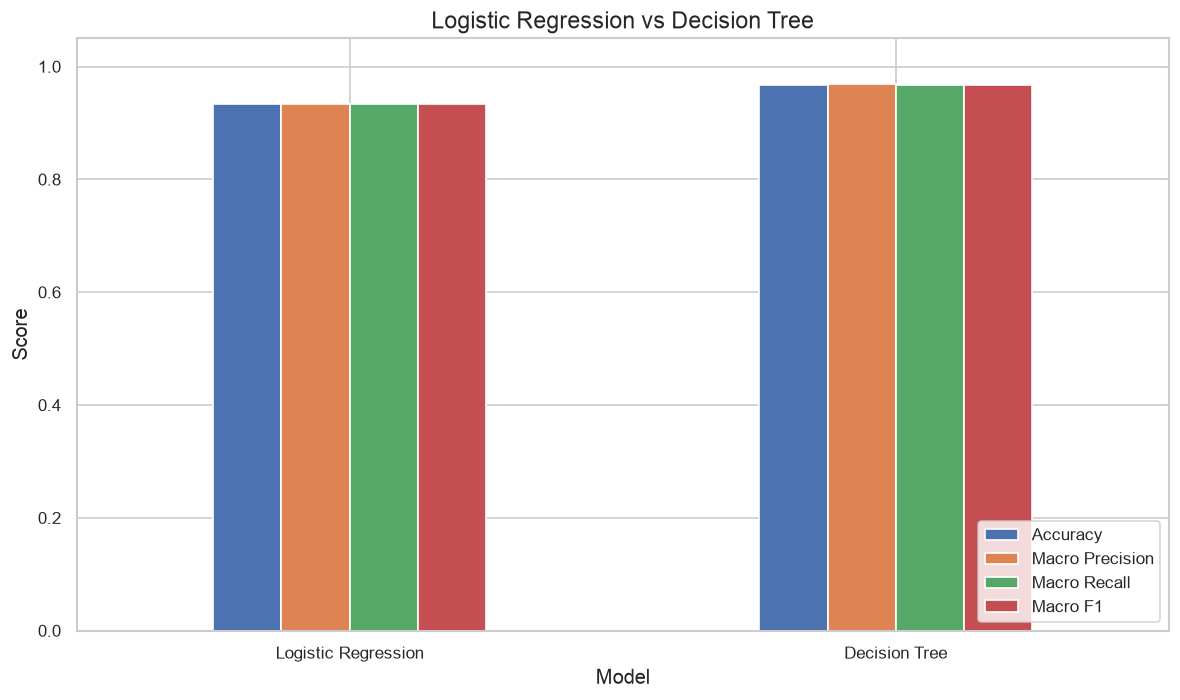

In [46]:
comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.legend(loc="lower right")

plt.tight_layout()

plt.show()